In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

In [3]:
df = pd.read_csv('/Users/raychielle/Desktop/nova_pay/fraudulent_transaction_detector/data/nova_pay_combined.csv')

In [4]:
df.head()

,transaction_id,customer_id,timestamp,home_country,source_currency,dest_currency,channel,amount_src,amount_usd,fee,...,ip_risk_score,kyc_tier,account_age_days,device_trust_score,chargeback_history_count,risk_score_internal,txn_velocity_1h,txn_velocity_24h,corridor_risk,is_fraud
0,fee8542d-8ee6-4b0d-9671-c294dd08ed26,402cccc9-28de-45b3-9af7-cc5302aa1f93,2022-10-03 18:40:59.468549+00:00,US,USD,CAD,ATM,278.19,278.19,4.25,...,0.123,standard,263,0.522,0,0.223,0,0,0.0,0
1,bfdb9fc1-27fe-4a85-b043-4d813d679259,67c2c6b3-ef0a-4777-a3f1-c84a851bb6ad,2022-10-03 20:39:38.468549+00:00,CA,CAD,MXN,web,208.51,154.29,4.24,...,0.569,standard,947,0.475,0,0.268,0,1,0.0,0
2,fc855034-3ea5-4993-9afa-b511d93fe5e8,6d0d9b27-fa26-45f8-93b1-2df29d182d9c,2022-10-03 23:02:43.468549+00:00,US,USD,CNY,mobile,160.33,160.33,2.70,...,0.437,enhanced,367,0.939,0,0.176,0,0,0.0,0
3,2cf8c08e-42ec-444d-a755-34b9a2a0a4ca,7bd5200c-5d19-44f0-9afe-8b339a05366b,2022-10-04 01:08:53.468549+00:00,US,USD,EUR,mobile,59.41,59.41,2.22,...,0.594,standard,147,0.551,0,0.391,0,0,0.0,0
4,d907a74d-b426-438d-97eb-dbe911aca91c,70a93d26-8e3a-4179-900c-a4a7a74d08e5,2022-10-04 09:35:03.468549+00:00,US,USD,INR,mobile,200.96,200.96,3.61,...,0.121,enhanced,257,0.894,0,0.257,0,0,0.0,0


## Data Quality Assessment

In [5]:
round(df.isnull().mean() * 100, 2)

transaction_id               0.00
customer_id                  0.00
timestamp                    0.25
home_country                 0.00
source_currency              0.00
dest_currency                0.00
channel                      0.00
amount_src                   0.00
amount_usd                   2.68
fee                          2.59
exchange_rate_src_to_dest    0.00
device_id                    0.00
new_device                   0.00
ip_address                   2.68
ip_country                   2.64
location_mismatch            0.00
ip_risk_score                0.00
kyc_tier                     2.63
account_age_days             0.00
device_trust_score           2.59
chargeback_history_count     0.00
risk_score_internal          0.00
txn_velocity_1h              0.00
txn_velocity_24h             0.00
corridor_risk                0.00
is_fraud                     0.00
dtype: float64

### Alternatively, we could do a full categorical audit

In [6]:
for col in df.select_dtypes(include=['object']).columns.tolist():
    print(df[col].value_counts())
    print( '----------------------------------' )

transaction_id
9cfbbce9-979c-4d34-bf5a-98531362bd9a    2
1c925529-c86f-4910-86e8-e4d83cebfd37    2
a9198fb0-d831-48df-b434-c30a39078aa3    2
70ae28a6-f5d4-4cda-8317-994c115abf8d    2
c2c365cb-83d0-4433-aa4a-d7ffceeab4f6    2
                                       ..
c195dd6e-58b4-442c-9cc4-98adb52c68f0    1
13933d53-bac4-4e17-9db1-b1b779360ecb    1
cc899474-3aed-4cd5-9172-21ab44117d31    1
72a1d0c8-3f08-406d-b568-5364d01b92a8    1
fdffeb16-192a-4483-9b1e-9928e23269c2    1
Name: count, Length: 11200, dtype: int64
----------------------------------
customer_id
402cccc9-28de-45b3-9af7-cc5302aa1f93    1510
d71c91b4-fee8-4104-9856-a5c6109a62e3    1355
7041b9c1-3719-4ca8-9a6b-811b47cea6c0    1345
6d0d9b27-fa26-45f8-93b1-2df29d182d9c    1066
af8ca4c4-8703-4c55-b66c-2b76cd70040d     915
                                        ... 
aabb3f37-897d-494d-8692-61cafe6d4bfe       1
674b253e-6d4a-43a1-9972-dab8ea3ce646       1
3744e498-db4c-49b0-b158-0adad1bd06bf       1
a43936be-6797-4948-9c02-979b66

### From the audit we found 'Inconsistent casing and typos (Mobille, weeb, ATm, standrd, enhancd, etc)
### Placeholder 'Unknown', whitespaces, nan/NAN placeholders, leading/trailing whitespaces.

In [7]:
### Check for duplicates
df.duplicated().sum()

np.int64(200)

In [8]:
### Check for data types
df.dtypes

transaction_id                object
customer_id                   object
timestamp                     object
home_country                  object
source_currency               object
dest_currency                 object
channel                       object
amount_src                    object
amount_usd                   float64
fee                          float64
exchange_rate_src_to_dest    float64
device_id                     object
new_device                      bool
ip_address                    object
ip_country                    object
location_mismatch               bool
ip_risk_score                float64
kyc_tier                      object
account_age_days               int64
device_trust_score           float64
chargeback_history_count       int64
risk_score_internal          float64
txn_velocity_1h                int64
txn_velocity_24h               int64
corridor_risk                float64
is_fraud                       int64
dtype: object

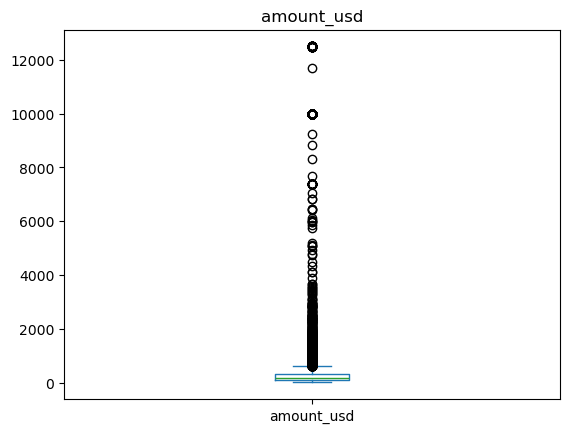

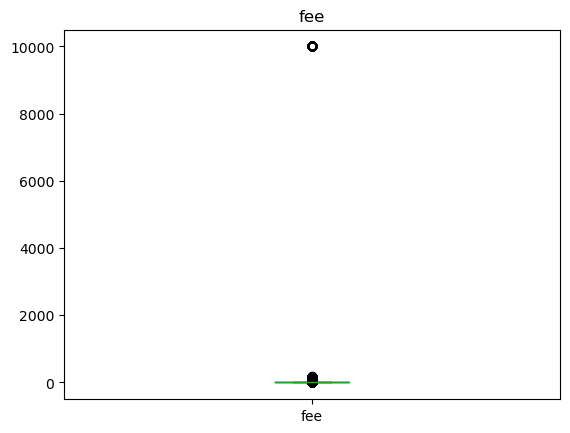

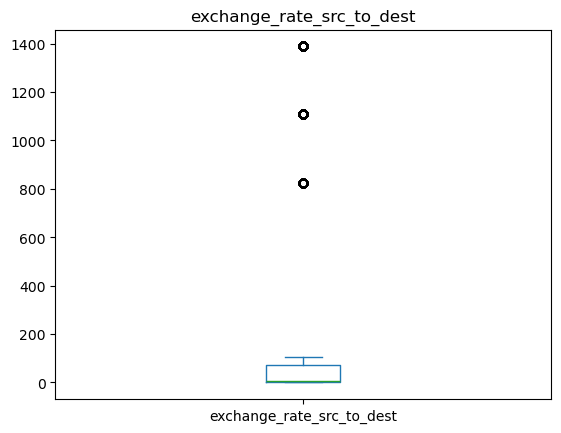

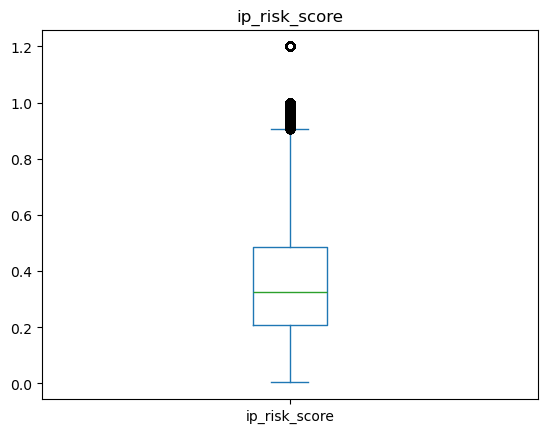

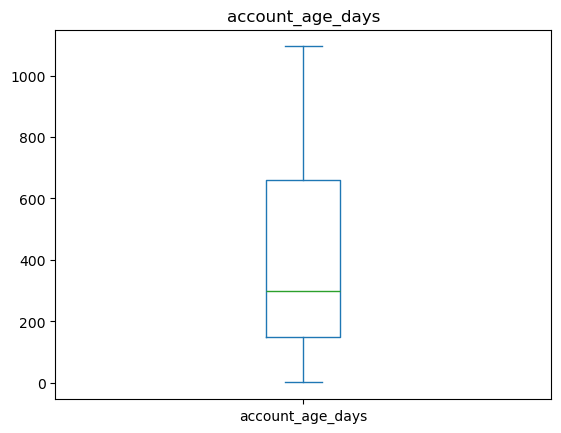

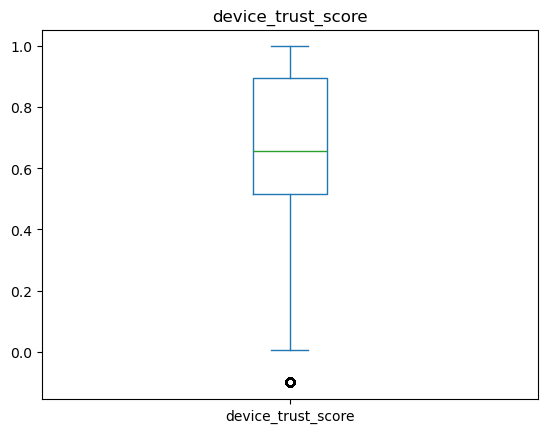

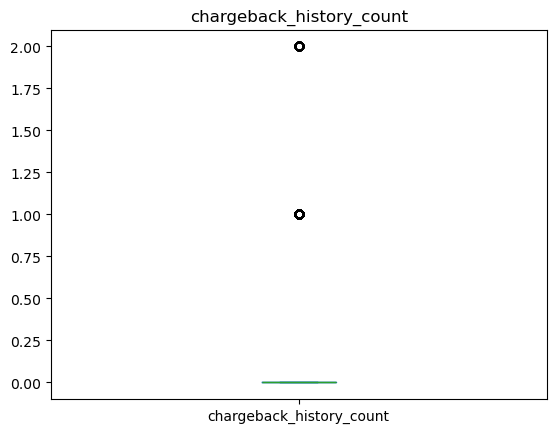

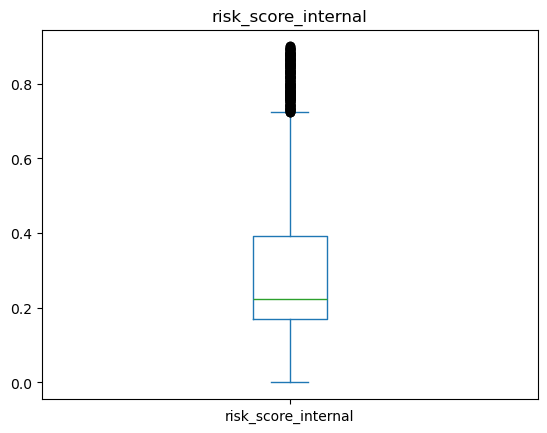

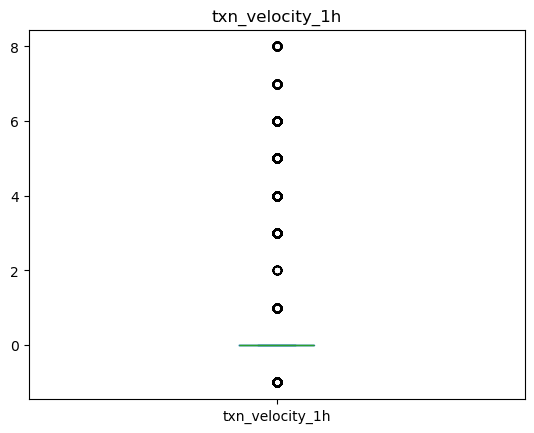

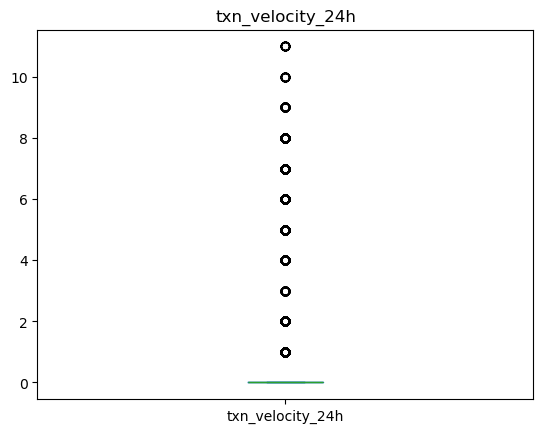

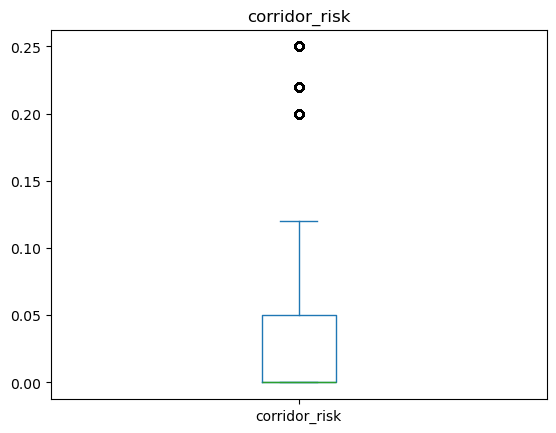

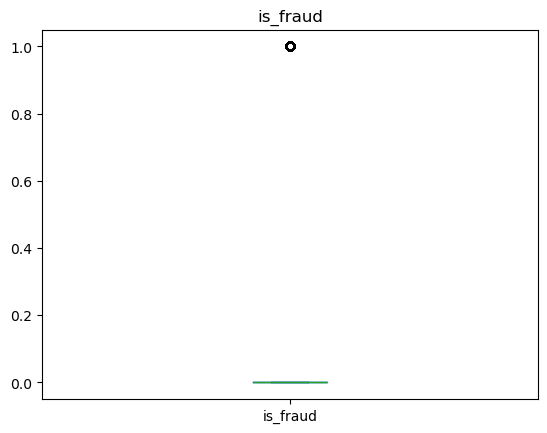

In [9]:
## Check for outliers in all numerical columns with boxplots
for col in df.select_dtypes(include=np.number).columns.tolist():
    df[col].plot(kind='box', title=col)
    plt.show()

### Data Cleaning and Standardization

In [10]:
df[df['txn_velocity_1h'] < 0][['txn_velocity_1h', 'fee', 'is_fraud', 'amount_usd']].sample(30)

,txn_velocity_1h,fee,is_fraud,amount_usd
4229,-1,-1.00,0,127.53
5521,-1,-1.00,0,NaN
8055,-1,-1.00,0,150.36
3327,-1,9999.99,0,32.25
4927,-1,9999.99,0,40.47
7818,-1,-1.00,0,204.94
4657,-1,-1.00,0,144.56
8566,-1,-1.00,0,233.90
3320,-1,9999.99,0,57.23
353,-1,-1.00,0,473.89


In [11]:
#reparse timestamp and amount_src

df['timestamp'] = pd.to_datetime(df['timestamp'], errors='coerce', dayfirst=True)
df['amount_src'] = pd.to_numeric(df['amount_src'], errors='coerce')

In [12]:
### Drop duplicates

df.drop_duplicates(subset=['transaction_id', 'customer_id', 'device_id', 'ip_address'], inplace=True)

In [13]:
### Correct issues with the categorical columns
cat_cols = df.select_dtypes(include=['object']).drop(columns=['transaction_id', 'customer_id', 'device_id', 'ip_address']).columns.tolist()

for col in cat_cols:
    df[col] = df[col].str.strip().str.lower()

typo_corrections = {
    'ip_country': {'nan': 'unknown'},
    'kyc_tier': {'nan': 'unknown', 'standrd': 'standard', 'enhancd': 'enhanced'},
    'channel': {'weeb': 'web', 'mobille': 'mobile'}
}

for col, corrections in typo_corrections.items():
    df[col] = df[col].replace(corrections)

In [14]:
### Missing values (convert negative values to absolute values)
df['amount_src'] = df['amount_src'].abs()

In [15]:
## fill missing values with median
df['amount_src'] = df['amount_src'].fillna(df['amount_src'].median())

In [16]:
### calculate rates conversion based on the data and return the values
rates = round((df['amount_usd']/df['amount_src']).groupby(df['source_currency']).mean(), 2)
print(rates.values)

### fill amount_usd with amount_src and rates
df['amount_usd'] = df['amount_usd'].fillna(df['amount_src'] * df['source_currency'].map(rates))

[0.74 1.29 1.02]


In [17]:
missing = df.isnull().sum()
missing_percent = (missing / len(df) * 100).round(2)

In [18]:
df['fee'] = df.groupby('channel')['fee'].transform(lambda x: x.fillna(x.median()))
df['fee']

0         4.25
1         4.24
2         2.70
3         2.22
4         3.61
         ...  
11395     5.24
11396     8.86
11397     4.00
11398     1.96
11399    19.34
Name: fee, Length: 11200, dtype: float64

In [19]:
### ip_country
df['ip_county'] = df['ip_country'].fillna(df['home_country'])

In [20]:
#### device trust score
df['device_trust_score'] = df['device_trust_score'].fillna(df['device_trust_score'].median())

In [21]:
df = df.dropna(subset=['timestamp'])

In [22]:
#Interquartile fee range
Q1 = df['fee'].quantile(0.25)
Q3 = df['fee'].quantile(0.75)

IQR = Q3 - Q1
lower_bound = Q1 - (100 * IQR)
upper_bound = Q3 + (100 * IQR)

print(lower_bound)
print(upper_bound)

df[(df['fee'] < lower_bound) | (df['fee'] > upper_bound)]

-307.56
315.54


,transaction_id,customer_id,timestamp,home_country,source_currency,dest_currency,channel,amount_src,amount_usd,fee,...,kyc_tier,account_age_days,device_trust_score,chargeback_history_count,risk_score_internal,txn_velocity_1h,txn_velocity_24h,corridor_risk,is_fraud,ip_county
328,3bcab4c7-dc2e-416c-b57e-266aafe46a47,d71c91b4-fee8-4104-9856-a5c6109a62e3,2022-10-11 03:14:05.468549+00:00,us,usd,ngn,mobile,37.08,37.08,9999.99,...,standard,298,-0.1,0,0.166,-1,0,0.25,0,us
564,8e0f5d06-a518-4b0c-ab83-5208837bc5be,af8ca4c4-8703-4c55-b66c-2b76cd70040d,2022-07-12 17:24:01.468549+00:00,us,usd,usd,web,176.92,176.92,9999.99,...,standard,1018,-0.1,0,0.087,-1,0,0.00,0,us
576,064c0207-1b3c-4328-b0b9-7ea68a70ee1f,6d0d9b27-fa26-45f8-93b1-2df29d182d9c,2022-08-12 16:48:52.468549+00:00,us,usd,cad,mobile,702.71,702.71,9999.99,...,enhanced,367,-0.1,0,0.176,-1,0,0.00,0,us
602,1d2465a1-14b6-48d9-a74d-76a2dddf5e65,67c2c6b3-ef0a-4777-a3f1-c84a851bb6ad,2022-11-12 19:23:29.468549+00:00,ca,cad,cad,web,203.83,150.83,9999.99,...,standard,947,-0.1,0,0.268,-1,0,0.00,0,ca
798,883403f5-fd2f-4b39-824e-9710485a983e,7041b9c1-3719-4ca8-9a6b-811b47cea6c0,2023-01-01 02:40:14.468549+00:00,uk,gbp,php,mobile,168.96,211.20,9999.99,...,standard,4,-0.1,0,0.407,-1,0,0.00,0,uk
1418,ae0c1cd8-7f7e-4424-938f-7f7242ff197f,402cccc9-28de-45b3-9af7-cc5302aa1f93,2023-11-03 14:21:45.468549+00:00,us,usd,gbp,web,504.71,504.71,9999.99,...,standard,263,-0.1,0,0.223,-1,0,0.00,0,us
1429,873a17a6-91b1-434c-9908-2bf57fefa746,402cccc9-28de-45b3-9af7-cc5302aa1f93,2023-12-03 19:53:56.468549+00:00,us,usd,ngn,web,144.10,144.10,9999.99,...,standard,263,-0.1,0,0.223,-1,0,0.25,0,us
1664,00ceaf20-a2a2-4cf9-9f02-15445a15e48c,d71c91b4-fee8-4104-9856-a5c6109a62e3,2023-05-04 21:17:25.468549+00:00,us,usd,php,atm,59.01,59.01,9999.99,...,standard,298,-0.1,0,0.166,-1,0,0.10,0,us
1943,6e8ae26b-ef8b-4663-b806-ccd782e0b8bc,f7531a78-8bbe-4a85-b1e8-a0650edddc72,2023-06-05 15:57:39.468549+00:00,us,usd,php,mobile,251.88,251.88,9999.99,...,standard,1016,-0.1,0,0.247,-1,3,0.10,0,us
2484,55d4247c-7403-4b36-9d27-a092f6880652,d71c91b4-fee8-4104-9856-a5c6109a62e3,2023-04-07 23:20:43.468549+00:00,us,usd,php,web,153.12,153.12,9999.99,...,standard,298,-0.1,0,0.166,-1,0,0.10,0,us


In [23]:
print((df['amount_src'] < 0).sum())
df['amount_src'] = df['amount_src'].abs()

0


#### Replace Outliers with Trimmed Mean

In [24]:
outlier = (df['fee'] < lower_bound) | (df['fee'] > upper_bound)
trimmed_mean = df.loc[~outlier, 'fee'].mean()

print(round(trimmed_mean, 3))

df.loc[outlier, 'fee'] = round(trimmed_mean, 3)

7.908


In [25]:
### Drop Unnecessary Columns
df.drop(columns=['transaction_id', 'customer_id', 'device_id', 'ip_address'], inplace=True)

In [26]:
df.isnull().sum()

timestamp                      0
home_country                   0
source_currency                0
dest_currency                  0
channel                        0
amount_src                     0
amount_usd                     0
fee                            0
exchange_rate_src_to_dest      0
new_device                     0
ip_country                   118
location_mismatch              0
ip_risk_score                  0
kyc_tier                     118
account_age_days               0
device_trust_score             0
chargeback_history_count       0
risk_score_internal            0
txn_velocity_1h                0
txn_velocity_24h               0
corridor_risk                  0
is_fraud                       0
ip_county                      0
dtype: int64

In [27]:
df.head()

,timestamp,home_country,source_currency,dest_currency,channel,amount_src,amount_usd,fee,exchange_rate_src_to_dest,new_device,...,kyc_tier,account_age_days,device_trust_score,chargeback_history_count,risk_score_internal,txn_velocity_1h,txn_velocity_24h,corridor_risk,is_fraud,ip_county
0,2022-03-10 18:40:59.468549+00:00,us,usd,cad,atm,278.19,278.19,4.25,1.351351,False,...,standard,263,0.522,0,0.223,0,0,0.0,0,us
1,2022-03-10 20:39:38.468549+00:00,ca,cad,mxn,web,208.51,154.29,4.24,12.758621,True,...,standard,947,0.475,0,0.268,0,1,0.0,0,ca
2,2022-03-10 23:02:43.468549+00:00,us,usd,cny,mobile,160.33,160.33,2.70,7.142857,False,...,enhanced,367,0.939,0,0.176,0,0,0.0,0,us
3,2022-04-10 01:08:53.468549+00:00,us,usd,eur,mobile,59.41,59.41,2.22,0.925926,False,...,standard,147,0.551,0,0.391,0,0,0.0,0,us
4,2022-04-10 09:35:03.468549+00:00,us,usd,inr,mobile,200.96,200.96,3.61,83.333333,False,...,enhanced,257,0.894,0,0.257,0,0,0.0,0,us


In [28]:
df.shape

(4221, 23)

## Train the Base Model

- Split data into Train and Test
- Standardize and Encode
- Train Base Model
    - Instantiate the Model
    - Fit the Model
    - Run prediction
    - Lastly, evaluate against the test set.


In [29]:
from sklearn.linear_model import LogisticRegression
from sklearn.compose import ColumnTransformer
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder

In [30]:
model_data = df.copy()

In [31]:
model_data = model_data.sort_values('timestamp').reset_index(drop=True)

X = model_data.drop(columns=['is_fraud', 'timestamp'])
y = model_data['is_fraud']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=False)

In [32]:
categorical_columns = X_train.select_dtypes(include=['object']).columns.tolist()
numerical_columns = X_train.select_dtypes(include=['number', 'bool']).columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_columns),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_columns)
    ]
)

X_train_transformed = preprocessor.fit_transform(X_train)
X_test_transformed = preprocessor.transform(X_test)

In [33]:
model = LogisticRegression(random_state=42, class_weight='balanced')
model.fit(X_train_transformed, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,'balanced'
,random_state,42
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [34]:
y_pred = model.predict(X_test_transformed)

              precision    recall  f1-score   support

   Not Fraud       0.98      0.94      0.96       744
       Fraud       0.67      0.89      0.76       101

    accuracy                           0.93       845
   macro avg       0.83      0.92      0.86       845
weighted avg       0.95      0.93      0.94       845



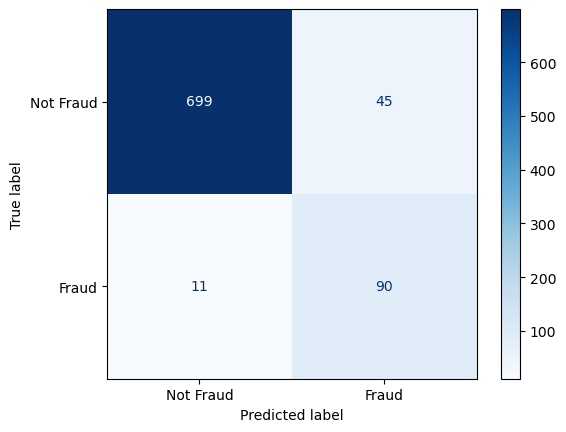

In [35]:
print(classification_report(y_test, y_pred, target_names=['Not Fraud', 'Fraud']))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=['Not Fraud', 'Fraud'], cmap="Blues")

In [40]:
import lightgbm as lgb
from sklearn.pipeline import Pipeline

In [41]:
model_lgb = Pipeline(steps=[
    ("preprocessor", preprocessor),   
    ("classifier", lgb.LGBMClassifier(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=6,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

model_lgb.fit(X_train, y_train)

y_pred = model_lgb.predict(X_test)
print(classification_report(y_test, y_pred, target_names=["Not Fraud", "Fraud"]))

[LightGBM] [Info] Number of positive: 299, number of negative: 3077
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000477 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1653
[LightGBM] [Info] Number of data points in the train set: 3376, number of used features: 43
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=-0.000000
[LightGBM] [Info] Start training from score -0.000000
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -

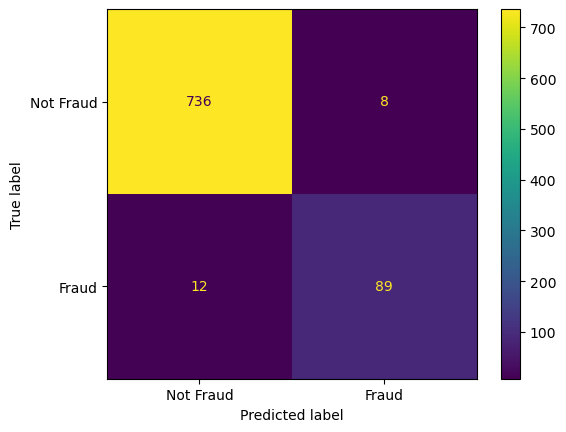

In [42]:
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=["Not Fraud", "Fraud"]
)
plt.show()